# Optimiser votre réseau
**ÉNONCÉ** · durée estimée : une demi-journée

## 🧭 Où vous allez
Vous avez un premier réseau (TP B). Ici, vous apprenez à **l'améliorer sans vous tromper**, puis à **l'alléger**. Vous finissez avec **un tableau de résultats chiffrés** et une conclusion honnête.

## Deux mots à connaître
- Les **paramètres** : les poids du réseau. **Il les apprend tout seul.**
- Les **hyperparamètres** : les réglages que **vous** choisissez avant l'entraînement (nombre de neurones, taux d'apprentissage, dropout, nombre d'epochs…).

## Trois règles d'or
1. On **compare les réglages sur la validation**, jamais sur le test.
2. Un gain n'existe que s'il dépasse le **bruit** (le hasard d'un entraînement ou d'un jeu de textes).
3. Le jeu de test sert **une seule fois, à la fin**.

## Comment travailler
- Une seule grosse cellule, la **cellule d'expérience**, sert à tout. **Vous changez les valeurs dans son bloc « réglages »**, vous la relancez, et vous **notez le résultat dans le tableau**.
- Aucune fonction à écrire, aucune vérification automatique : vous comparez avec la zone **« Ce que vous devez voir »**.
- Des questions écrites montrent ce que vous avez compris.

`pip install pandas scikit-learn matplotlib tensorflow`

## Étape 1 — Importer les outils

In [54]:
import numpy as np                                            # calculs sur des tableaux de nombres
import pandas as pd                                           # tableaux de données (comme une table SQL)
import matplotlib.pyplot as plt                               # dessiner des graphiques
from sklearn.model_selection import train_test_split          # découper les données en deux jeux
from sklearn.feature_extraction.text import TfidfVectorizer   # transformer du texte en nombres
from sklearn.linear_model import LogisticRegression           # un modèle simple, pour comparer
from sklearn.metrics import confusion_matrix                  # compter les erreurs du modèle
from tensorflow import keras                                  # la bibliothèque de deep learning
from tensorflow.keras import layers                           # les couches de neurones
keras.utils.set_random_seed(42)                               # fixe le hasard : tout le monde obtient les mêmes résultats
import tensorflow as tf                                       # pour alléger le modèle à la fin
tf.get_logger().setLevel('ERROR')                             # réduit les messages de tensorglow aux erreurs

## Étape 2 — Charger le corpus
On lit le fichier de textes. **Si vous avez fait le TP A**, remplacez `corpus_secours.csv` par `corpus.csv`.

In [55]:
import os
DOSSIER_PROJET = "/mnt/c/Users/Utilisateur/TP-CODE/WebScrappingToRNN/corpus"
CHEMIN_CORPUS = os.path.join(DOSSIER_PROJET, "corpus.csv")

In [56]:
corpus = pd.read_csv(CHEMIN_CORPUS)   # lit le fichier CSV
print(corpus.shape)                          # (nombre de lignes, nombre de colonnes)
corpus.head()                                # affiche les 5 premières lignes

(1184, 4)


,classe,titre,texte,lien
0,Jeu,Game,A game is an activity defined by a challenge a...,/wiki/Game
1,Jeu,Clue (information),A clue or a hint is a piece of information bri...,/wiki/Clue_(information)
2,Jeu,Meitei traditional games,Meitei traditional games or Meitei indigenous ...,/wiki/Meitei_traditional_games
3,Jeu,Recreational mathematics,Recreational mathematics is mathematics carrie...,/wiki/Recreational_mathematics
4,Jeu,Dungeons & Dragons,Dungeons & Dragons (commonly abbreviated as D&...,/wiki/Dungeons_%26_Dragons


In [57]:
print(corpus["classe"].value_counts())   # combien de textes dans chaque classe ?

classe
Jeu            299
Histoire       299
Psychologie    297
Astronomie     289
Name: count, dtype: int64


## Étape 3 — Les classes en nombres
Un réseau ne manipule que des **nombres**. On remplace chaque nom de classe par un numéro : 0, 1, 2…

In [58]:
corpus["y"], noms = pd.factorize(corpus["classe"])   # y = le numéro de la classe de chaque texte
print(noms)                                           # la correspondance : la position dans la liste = le numéro
n_classes = len(noms)                                 # le nombre de classes à reconnaître
print("Nombre de classes :", n_classes)

Index(['Jeu', 'Astronomie', 'Histoire', 'Psychologie'], dtype='str')
Nombre de classes : 4


## Étape 4 — Découper : un jeu pour apprendre, un jeu pour vérifier
On garde **25 % des textes de côté**. Le réseau ne les verra **jamais** pendant son apprentissage : c'est notre examen final.

In [59]:
train, test = train_test_split(corpus, test_size=0.25, stratify=corpus["y"], random_state=42)
print("Textes pour apprendre :", len(train))
print("Textes pour vérifier  :", len(test))

Textes pour apprendre : 888
Textes pour vérifier  : 296


## Étape 5 — Transformer les textes en nombres (TF-IDF)
Chaque texte devient une ligne de **2 000 nombres** : un nombre par mot du vocabulaire. Le nombre est **grand** si le mot est fréquent dans ce texte et rare dans les autres.

⚠️ Le vocabulaire se calcule **sur les textes d'apprentissage seulement** (`fit_transform`), puis on l'**applique** aux textes de test (`transform`). Sinon le test « souffle » des informations au modèle.

In [60]:
vectoriseur = TfidfVectorizer(max_features=2000, stop_words="english")   # on garde les 2000 mots les plus utiles
X_train = vectoriseur.fit_transform(train["texte"])    # apprend le vocabulaire ET transforme les textes d'apprentissage
X_test = vectoriseur.transform(test["texte"])          # applique le même vocabulaire aux textes de test
X_train = X_train.toarray().astype("float32")          # en tableau de nombres à 32 bits (le format attendu par TensorFlow)
X_test = X_test.toarray().astype("float32")
y_train = train["y"].values                            # la bonne réponse de chaque texte d'apprentissage
y_test = test["y"].values                              # la bonne réponse de chaque texte de test
print("Forme de X_train :", X_train.shape, "(textes, mots)")

Forme de X_train : (888, 2000) (textes, mots)


## Étape 6 — Un troisième jeu : la validation
Pour **comparer des réglages**, on ne touche pas au jeu de test (réservé au verdict final). On met de côté **20 % de l'apprentissage** : ce sont les textes de **validation**.

In [61]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
nb_mots = X_tr.shape[1]                                # nombre de colonnes = nombre de mots du vocabulaire
print("Pour apprendre :", len(y_tr), "| pour comparer les réglages :", len(y_val), "| pour le verdict final :", len(y_test))

Pour apprendre : 710 | pour comparer les réglages : 178 | pour le verdict final : 296


**Ce que vous devez voir :** `Pour apprendre : 1800 | pour comparer les réglages : 450 | pour le verdict final : 750` avec le corpus de secours. Avec votre corpus, les nombres sont plus petits.

## Étape 7 — La cellule d'expérience, ligne par ligne
La cellule suivante contient **tout** : les réglages, la construction du réseau, l'entraînement et le résultat. Elle est découpée en 4 blocs par des commentaires `# -----`.

| Bloc | Ce qu'il fait |
|---|---|
| **Les réglages** | Des variables que **vous** modifiez. Rien d'autre à toucher. |
| **Le réseau** | Empile les couches, comme au TP B, avec les valeurs des réglages. |
| **L'entraînement** | `fit` : le réseau apprend sur les textes d'apprentissage (`X_tr`) et se surveille sur la validation (`X_val`). |
| **Le résultat** | La précision sur la validation, deux mesures de la perte, le nombre d'epochs et de paramètres. |

Le **taux d'apprentissage** (`taux`) est la **taille du pas** de chaque correction : trop petit, le réseau apprend lentement ; trop grand, il saute par-dessus la bonne solution.

**Première exécution : ne changez rien.** C'est votre **point de départ**.

In [85]:
# ----- Les réglages : c'est ICI que vous changez les valeurs -----
taux = 0.001            # taux d'apprentissage : la taille de chaque pas de correction
neurones1 = 8          # nombre de neurones de la 1re couche cachée
neurones2 = 4          # nombre de neurones de la 2e couche cachée
dropout = 0.0           # part de neurones éteints au hasard à chaque pas (0.0 = aucun)
epochs = 30             # nombre de passages complets sur les textes d'apprentissage
n_exemples = 100000     # nombre de textes d'apprentissage utilisés (s'il y en a moins, il les prend tous)
graine = 42             # la graine du hasard
rappels = []            # pour l'arrêt précoce : remplacez [] par [arret]

# ----- Le réseau (ne rien changer) -----
keras.utils.set_random_seed(graine)                       # fixe le hasard
reseau = keras.Sequential()                               # un réseau vide
reseau.add(layers.Input(shape=(nb_mots,)))                # l'entrée : un nombre par mot
reseau.add(layers.Dense(neurones1, activation="relu"))    # 1re couche cachée
reseau.add(layers.Dropout(dropout))                       # éteint au hasard une part des neurones (si dropout > 0)
reseau.add(layers.Dense(neurones2, activation="relu"))    # 2e couche cachée
reseau.add(layers.Dropout(dropout))
reseau.add(layers.Dense(n_classes, activation="softmax")) # sortie : une probabilité par classe
reseau.compile(optimizer=keras.optimizers.Adam(learning_rate=taux), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# ----- L'entraînement (ne rien changer) -----
histoire = reseau.fit(X_tr[:n_exemples], y_tr[:n_exemples], validation_data=(X_val, y_val), epochs=epochs, batch_size=32, callbacks=rappels, verbose=0)

# ----- Le résultat (ne rien changer) -----
reponses_val = np.argmax(reseau.predict(X_val, verbose=0), axis=1)   # la réponse du réseau pour chaque texte de validation
precision_val = np.mean(reponses_val == y_val)                       # part de bonnes réponses
print("Précision sur les textes de validation :", round(precision_val, 3))
print("Perte de validation minimale :", round(min(histoire.history["val_loss"]), 3))
print("Perte de validation finale   :", round(histoire.history["val_loss"][-1], 3))
print("Nombre d'epochs effectués    :", len(histoire.history["loss"]))
print("Nombre de paramètres         :", reseau.count_params())

I0000 00:00:1792155359.936411   11689 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_114191__.13
I0000 00:00:1792155360.656695   11686 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_114191__.13


Précision sur les textes de validation : 0.753
Perte de validation minimale : 0.705
Perte de validation finale   : 0.705
Nombre d'epochs effectués    : 30
Nombre de paramètres         : 16064


**Ce que vous devez voir :** une précision de validation autour de `0.8`, quelques epochs, et `130243` paramètres (corpus de secours). **Notez cette précision** : c'est votre point de départ.

Point de départ :
Précision sur les textes de validation : 0.844
Perte de validation minimale : 0.55
Perte de validation finale   : 0.55
Nombre d'epochs effectués    : 30
Nombre de paramètres         : 130276

## Étape 8 — Expérience 1 : le taux d'apprentissage
**Prédisez d'abord** lequel des quatre sera le meilleur.

**À faire :** dans la cellule d'expérience, changez **seulement** `taux` : `0.0001`, puis `0.001`, `0.01`, `0.1`. À chaque fois, relancez la cellule et notez la précision de validation.

| taux d'apprentissage | précision de validation |
|---|---|
| 0.0001 | 0.644 |
| 0.001 | 0.844 |
| 0.01 | 0.778 |
| 0.1 | 0.644 |

## Étape 9 — Expérience 2 : la taille du réseau
**À faire :** remettez `taux = 0.001`, puis changez **les deux nombres de neurones ensemble** : `4` et `2`, puis `16` et `8`, puis `64` et `32`, puis `256` et `128`. Notez la précision et le nombre de paramètres.

| neurones couche 1 | neurones couche 2 | précision de validation | nombre de paramètres |
|---|---|---|---|
| 4 | 2 | 0.444 | 8026|
| 16 | 8 | 0.822 | 32188 |
| 64 | 32 | 0.844 | 130276 |
| 256 | 128 | 0.822 | 545668 |

## Étape 10 — Une différence est-elle réelle ? Le bruit
Avec peu de textes de validation, la précision mesurée est **incertaine** : un autre jeu de textes donnerait un résultat un peu différent. Cette incertitude se calcule. Elle vaut environ `1,96 × racine( p × (1 − p) ÷ n )`, où `p` est la précision et `n` le nombre de textes.

**Une différence plus petite que cette marge n'est pas une amélioration démontrée.**

In [81]:
n_val = len(y_val)                                   # nombre de textes de validation
p = 0.8                                               # une précision approximative (celle que vous avez obtenue)
bruit = 1.96 * np.sqrt(p * (1 - p) / n_val)           # la marge d'incertitude
print("Nombre de textes de validation :", n_val)
print("Marge d'incertitude (bruit) :", round(bruit, 3))

Nombre de textes de validation : 178
Marge d'incertitude (bruit) : 0.059


### ✍️ Question
**Regardez vos deux tableaux. Quels écarts dépassent la marge d'incertitude ? Lesquels ne prouvent rien ?**

*Votre réponse :*

> La precision selon le taux d'apprentissage sont tous soumis a la marge d'erreur (0.117), cependant la precision selon le nombre de neurones a besoin d'un nombre de neurones minimal pour commencer a entrer dans la marge d'erreur (le 4*2 est trop peu précis). Le corpus est trop petit pour etre véritablement précis.

## Étape 11 — Provoquer le surapprentissage
Pour voir la **mémorisation**, on donne **peu de textes** (200) à un **gros réseau** (256 et 128 neurones) pendant **100 epochs**.

**À faire :** remettez les réglages par défaut (`taux = 0.001`, `dropout = 0.0`, `rappels = []`, `graine = 42`), puis changez `neurones1 = 256`, `neurones2 = 128`, `epochs = 100`, `n_exemples = 200`. Relancez, puis exécutez la cellule des courbes juste après.

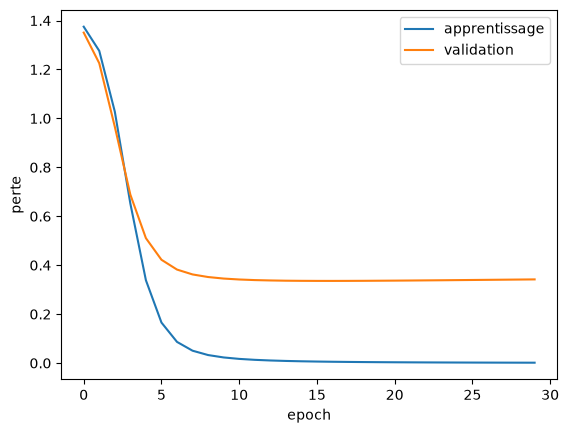

In [71]:
plt.plot(histoire.history["loss"], label="apprentissage")   # perte sur les textes d'apprentissage
plt.plot(histoire.history["val_loss"], label="validation")   # perte sur les textes de validation
plt.xlabel("epoch")
plt.ylabel("perte")
plt.legend()
plt.show()

**Ce que vous devez voir :** la perte d'apprentissage descend vers 0 ; la perte de validation descend d'abord, puis **remonte**. C'est la mémorisation. Notez les deux valeurs de perte de validation (minimale, finale) dans le tableau plus bas.

## Étape 12 — Soigner le surapprentissage
Deux remèdes simples :
- le **dropout** : à chaque pas, on éteint au hasard une part des neurones, pour que le réseau ne s'appuie pas sur un seul ;
- l'**arrêt précoce** : on arrête quand la perte de validation ne s'améliore plus pendant 5 epochs, et on **reprend les meilleurs poids**.

On définit d'abord l'arrêt précoce (une seule fois) :

In [82]:
arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)   # arrête si la perte de validation stagne 5 epochs, et garde les meilleurs poids
print("Arrêt précoce défini")

Arrêt précoce défini


**À faire :** gardez les réglages du surapprentissage (256, 128, 100 epochs, 200 textes), puis lancez **deux essais** : un avec `dropout = 0.5`, un avec `rappels = [arret]`. Remplissez le tableau.

| Essai | perte de validation minimale | perte de validation finale | epochs effectués | précision de validation |
|---|---|---|---|---|
| sans remède | 0.489 | 0.496 | 100 | 0.8 |
| dropout = 0.5 | 0.528 | 0.566 | 100 | 0.8 |
| arrêt précoce | 0.489 | 0.49 | 51 | 0.822 |

### ✍️ Question
**Quel remède réduit le plus la perte de validation finale ? Un remède réduit-il toujours la perte ?**

*Votre réponse :*

> l'arret précoce réduit le plus la perte de validation finale. Non, un remède ne réduit pas toujours la perte, comme on peut le voir avec le dropout qui l'a empirée.

## Étape 13 — Le hasard : la graine
Deux entraînements du **même** réseau donnent des résultats un peu différents : les **poids de départ** sont tirés au hasard. La **graine** (`graine`, comme `random_state` dans scikit-learn) fixe ce hasard : même graine, mêmes résultats ; autre graine, autre résultat.

**À faire :** remettez les réglages par défaut, puis lancez la cellule d'expérience **5 fois**, en changeant seulement `graine` : `0`, `1`, `2`, `3`, `4`. Notez les 5 précisions, puis recopiez-les dans la cellule du calcul.

In [66]:
# Précisions pour chaque graine : 0 -> 4

p0 = 0.8
p1 = 0.8
p2 = 0.844
p3 = 0.8
p4 = 0.8

In [67]:
scores = [p0, p1, p2, p3, p4]    # REMPLACEZ par VOS 5 précisions
print("Les 5 précisions :", scores)
print("Moyenne :", round(np.mean(scores), 3))
print("Écart-type (dispersion) :", round(np.std(scores), 3))

Les 5 précisions : [0.8, 0.8, 0.844, 0.8, 0.8]
Moyenne : 0.809
Écart-type (dispersion) : 0.018


### ✍️ Question
**Deux réglages diffèrent de 0,5 point de précision. Pouvez-vous dire que l'un est meilleur ?**

*Votre réponse :*

> Non. Premierement car on serait dans la marge d'erreur et de deux on peut voir que la graine peut aussi influencer le resultat final, dans notre cas jusqu'a 0.44.

## Étape 14 — Alléger le modèle (1/2) : la quantification
Un modèle plus léger coûte moins cher à héberger. La **quantification** stocke les poids sur **8 bits entiers** au lieu de 32 bits décimaux : ils sont **4 fois plus petits**.

**À faire d'abord :** remettez **tous** les réglages par défaut (`taux = 0.001`, `64`, `32`, `dropout = 0.0`, `30` epochs, `n_exemples = 100000`, `graine = 42`, `rappels = []`) et relancez la cellule d'expérience : le modèle à alléger est celui-là.

In [86]:
taille_avant = reseau.count_params() * 4                      # 4 octets par poids décimal (32 bits)
convertisseur = tf.lite.TFLiteConverter.from_keras_model(reseau)   # prépare la conversion
convertisseur.optimizations = [tf.lite.Optimize.DEFAULT]           # active la quantification
modele_leger = convertisseur.convert()                             # convertit : le résultat est un modèle léger
taille_apres = len(modele_leger)                                   # sa taille en octets
print("Taille des poids avant :", round(taille_avant / 1024), "Ko")
print("Taille après quantification :", round(taille_apres / 1024), "Ko")

Saved artifact at '/tmp/tmp4ohuexf6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 2000), dtype=tf.float32, name='keras_tensor_400')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  127571616093520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  127572817446672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  127571616102544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  127571616102160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  127571616101584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  127571616100816: TensorSpec(shape=(), dtype=tf.resource, name=None)
Taille des poids avant : 63 Ko
Taille après quantification : 18 Ko


W0000 00:00:1792155397.983709   11399 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792155397.983759   11399 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792155397.983955   11399 reader.cc:83] Reading SavedModel from: /tmp/tmp4ohuexf6
I0000 00:00:1792155397.984490   11399 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792155397.984501   11399 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp4ohuexf6
I0000 00:00:1792155397.988096   11399 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792155398.009060   11399 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp4ohuexf6
I0000 00:00:1792155398.016163   11399 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 32216 microseconds.


**Ce que vous devez voir :** deux tailles, environ `509 Ko` avant et `131 Ko` après : les poids sont environ **4 fois plus petits**. Des messages `INFO:tensorflow` s'affichent aussi : ils sont normaux.

## Étape 15 — Alléger le modèle (2/2) : la précision tient-elle ?
Un modèle plus léger ne vaut que si sa précision reste correcte. On compare, sur **300 textes de test** (le verdict final), le modèle d'origine et le modèle léger. La boucle `for` ci-dessous passe les 300 textes **un par un** dans le modèle léger.

## REMARQUE
> A partir de ce point j'ai changé de corpus pour passer de 300 a presque 1200 texte de base, ce qui change quelque peu les chiffres d'apprentissage et de precision.

In [69]:
print("Taille du corpus de test :", X_test.shape[0], " Taille attendue : 300")

Taille du corpus de test : 296  Taille attendue : 300


In [79]:
interpreteur = tf.lite.Interpreter(model_content=modele_leger)   # charge le modèle léger
interpreteur.allocate_tensors()                                      # prépare sa mémoire
entree = interpreteur.get_input_details()[0]["index"]                # où lui donner un texte
sortie = interpreteur.get_output_details()[0]["index"]               # où lire sa réponse
bonnes_reponses = 0                                                  # compteur de bonnes réponses
n_text = min(X_test.shape[0], 300)                                   # pour chacun des 300 premiers textes de test ou moins si le corpus est plus petit
for i in range(n_text):                                              
    un_texte = X_test[i:i+1]                                         # ...on prend un seul texte
    interpreteur.set_tensor(entree, un_texte)                        # on le donne au modèle léger
    interpreteur.invoke()                                            # le modèle léger calcule
    probas = interpreteur.get_tensor(sortie)                         # on lit ses probabilités
    if np.argmax(probas[0]) == y_test[i]:                            # si la classe de plus forte probabilité est la bonne...
        bonnes_reponses = bonnes_reponses + 1                        # ...on ajoute 1
precision_leger = bonnes_reponses / n_text
reponses_origine = np.argmax(reseau.predict(X_test[:n_text], verbose=0), axis=1)   # le modèle d'origine, sur les mêmes 300 textes
precision_origine = np.mean(reponses_origine == y_test[:n_text])
print("Précision du modèle d'origine :", round(precision_origine, 3))
print("Précision du modèle léger     :", round(precision_leger, 3))

/home/romain/venvs/WebScrappingToRNN/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Précision du modèle d'origine : 0.868
Précision du modèle léger     : 0.872


**Ce que vous devez voir :** un avertissement `deprecated` (sans importance), puis deux précisions **très proches** : le modèle léger garde presque toute la précision de l'original.

Résultat avec parametres de base :
Précision du modèle d'origine : 0.868
Précision du modèle léger     : 0.872

## Étape 16 — Alléger autrement : un plus petit réseau
L'autre façon d'alléger est de choisir **dès le départ un réseau plus petit**.

**À faire :** dans la cellule d'expérience, changez `neurones1 = 8` et `neurones2 = 4` (le reste par défaut), relancez, et notez la précision de validation et le nombre de paramètres.

Précision du modèle d'origine : 0.743
Précision du modèle léger     : 0.743


### ✍️ Question
**Quel compromis choisiriez-vous entre taille, précision et simplicité pour mettre ce modèle en production ? Justifiez avec vos chiffres.**

*Votre réponse :*

> Je privilégierais le modèle avec beaucoup de neurone (64/32) mais dans sa version quantifié (+légère), celle qui conserve la meilleure précision (87.2%) et qui est plus légère (poisds divisé par presque 4)

Précision sur les textes de validation : 0.753
Perte de validation minimale : 0.705
Perte de validation finale   : 0.705
Nombre d'epochs effectués    : 30
Nombre de paramètres         : 16064

## 📋 Tableau de synthèse à compléter
> Marge d'incertitude (bruit) : 0.059

| Version du modèle | Précision | Taille ou paramètres | Commentaire (gain réel ou bruit ?) |
|---|---|---|---|
| Réseau de départ (64 et 32) | 0.876 | 130276 / 509 Ko | modele de base |
| Meilleur taux d'apprentissage | | | |
| Avec dropout | 0.899 | 130276 | Gain dans la marge de bruit |
| Avec arrêt précoce | 0.876 | 130276 | Aucun gain |
| Arrêt précoce + Dropout | 0.876 | 130276 | Aucun gain |
| Quantifié | 0.872 | 131 Ko | Perte de précision minime <1% |
| Petit réseau (8 et 4) | 0.753 | 16064 / 63 Ko | Poids/8 pour une perte de précision de 12% |



> Dans notre cas, on est sur des modeles avec environ 100k parametres, donc on peut les entrainer, les stocker et les faires tourner facilement même en version non quantifiée. Dans la réalité les modeles actuels ont plusieurs milliard de paramatres, donc meme pour les plus petit, une version quantifiée est une bonne pratique pour une perte de précision acceptable au regard du gain en taille qui se chifre en Go (a la fois sur le disque mais aussi en RAM/VRAM)

## ✅ Ce qu'il faut retenir
- **Paramètres** : appris. **Hyperparamètres** : choisis par vous. On les compare **sur la validation**.
- Un gain n'existe que s'il dépasse le **bruit**, et un résultat dépend de la **graine**.
- **Surapprentissage** : la perte de validation remonte. Le **dropout** et l'**arrêt précoce** le limitent, mais ne marchent pas toujours.
- **Alléger** : quantification et plus petit réseau, avec un **compromis chiffré**.